# GIN — Recipe Tuning on Config 2 (HI-Small)

- **Question:** which training recipe (dropout, normalisation, depth, class weight, learning rate, FFN) should the GIN family use? Tuned **once** here on config 2 (mp base / readout base), then frozen for every GIN feature config.
- **Protocol (`EXPERIMENTS.md` §2b, fixed in advance):** one knob at a time in a pre-registered order — norm → layers → FFN → pos_weight → learning rate → dropout (architecture first, then optimizer, regularisation last) — starting from the v1 recipe; 2 seeds per trial, selection on validation only, cosine T_max 100 with early stopping, best epoch from the smoothed seed-mean validation curve; a trial replaces the incumbent only if it beats it by more than max(0.01, the larger seed std); the edge rule adds one trial one step beyond a winner at the edge of its grid.
- **Everything shared** lives in `gnn_core.py` (`run_tuning_trial`, `choose_winner`, `probe_depths`, `save_recipe`). This notebook only sets the operator, the stages and paths.
- **Never touches test:** only train and validation loaders are built, no `predictions.csv`. **Resumable:** a finished trial (`trial.json` committed in the repo) is skipped, so stages can span Kaggle sessions.

## 0. Environment (Kaggle)

- Pinned PyTorch / PyG stack known to work on Kaggle GPU — do not change versions or order.
- Then clone (or pull) the public repo so the committed `gnn_core.py` is the one imported.

In [1]:
!pip uninstall -y torch torchvision torchaudio torch-scatter torch-sparse pyg_lib
!pip install torch==2.8.0 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
!pip install torch-scatter torch-sparse torch-cluster -f https://data.pyg.org/whl/torch-2.8.0+cu126.html
!pip install torch_geometric

Found existing installation: torch 2.11.0+cu128
Uninstalling torch-2.11.0+cu128:
  Successfully uninstalled torch-2.11.0+cu128
Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 170.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 190.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 174.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 67.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 73.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 91.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import sys

REPO_URL = 'https://github.com/sandrokhizanishvili/gnn_for_fraudulent_patterns.git'
REPO_DIR = '/kaggle/working/gnn_for_fraudulent_patterns'
if os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO_URL} {REPO_DIR}
!git -C {REPO_DIR} log -1 --oneline
sys.path.append(REPO_DIR)

Cloning into '/kaggle/working/gnn_for_fraudulent_patterns'...
remote: Enumerating objects: 583, done.
remote: Counting objects: 100% (583/583), done.
remote: Compressing objects: 100% (509/509), done.
remote: Total 583 (delta 176), reused 468 (delta 67), pack-reused 0 (from 0)
Receiving objects: 100% (583/583), 24.04 MiB | 17.57 MiB/s, done.
Resolving deltas: 100% (176/176), done.
f820033 (HEAD -> main, origin/main, origin/HEAD) GIN_tuning.ipynb committed without outputs (GitHub 1 MB import limit); CLAUDE.md §7 records the exception


## 1. Configuration

- `STAGES`: the pre-registered knob order and grids; the winner of each stage is carried into the next.
- `TUNE`: the only change to the v1 recipe before tuning starts — cosine length 100 (early stopping decides the run length).
- `OUT_ROOT` sits **inside the repo clone**, so trials committed after an earlier session are found and skipped.

In [3]:
OPERATOR = 'gin'
CFG      = dict(mp='base', readout='base')     # config 2 — the configuration every recipe is tuned on
SEEDS    = (42, 43)                             # tuning seeds; the final retrain adds 44
TUNE     = dict(epochs=100)                     # v1 recipe + cosine T_max 100; nothing else changes before stage 1

# one knob at a time, architecture first, then optimizer, regularisation last (EXPERIMENTS.md section 2b);
# the incumbent value is in every grid, so the v1 recipe is the starting incumbent
STAGES = [
    ('s1_norm',       'norm',       ['none', 'batch', 'layer']),
    ('s2_layers',     'num_layers', [2, 4, 6]),
    ('s3_ffn',        'ffn',        [False, True]),
    ('s4_pos_weight', 'pos_weight', [8.0, 16.0]),
    ('s5_lr',         'lr',         [5e-4, 1e-3, 3e-3]),
    ('s6_dropout',    'dropout',    [0.2, 0.3, 0.4]),
]
PATIENCE, MIN_EPOCHS, EVAL_TRAIN_EVERY = 10, 20, 5   # early stopping on the smoothed val F1; train scored every 5th epoch
PROBE_DEPTHS = (2, 4, 6)                             # heaviest setting (BatchNorm + FFN) probed before stage 1

MP_DIRECTION      = 'in'     # fixed for the whole tuning
TEMPORAL_SAMPLING = False

# paths — OUT_ROOT inside the repo clone so committed trials resume
DATA_DIR = '/kaggle/input/datasets/sandrokhizanishvili/hi-small-gnn'
OUT_ROOT = f'{REPO_DIR}/Outputs/TUNING/{OPERATOR.upper()}'

import gnn_core as core
os.makedirs(OUT_ROOT, exist_ok=True)
print(f'torch {core.torch.__version__} | device {core.device} | gnn_core from {core.__file__}')
print(f'v1 recipe {core.full_recipe(None)}')
print(f'tuning starts from {core.full_recipe(TUNE)}')

torch 2.8.0+cu126 | device cuda | gnn_core from /kaggle/working/gnn_for_fraudulent_patterns/gnn_core.py
v1 recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 20, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}
tuning starts from {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}


## 2. Load graphs

- Three cumulative PyG snapshots; context edges carry label −1, only `eval_mask` edges are scored.
- Only train and validation are used here; the test snapshot is loaded (same loader as every notebook) but never read.

In [4]:
graphs, col_sets, node_dim = core.load_graphs(DATA_DIR)

edge_attr width 81 (base 20 + gfp 61, variant v0)
train nodes=515,070 edges=3,046,342 evaluated=3,046,342 laundering=2,297 (0.0754%)
val   nodes=515,070 edges=4,061,789 evaluated=1,015,447 laundering=1,082 (0.1066%)
test  nodes=515,070 edges=5,077,237 evaluated=1,015,448 laundering=1,143 (0.1126%)


## 3. Probe — memory and time per depth

- Per depth (2 / 4 / 6) at the heaviest setting (BatchNorm + FFN): 3 warm-up batches, 20 timed training batches with peak GPU memory, then one full prediction pass over the validation graph.
- A depth passes when it fits and its epoch estimate is ≤ 3× the 2-layer one; otherwise the far-hop fallback list is tried, then the depth is dropped.
- `NEIGHBOURS_USED` is what the stages run with; the full record goes to `probe.json`.

In [5]:
HEAVIEST = dict(TUNE, norm='batch', ffn=True)
probe = core.probe_depths(OPERATOR, CFG, graphs, col_sets, node_dim, HEAVIEST, PROBE_DEPTHS,
                          f'{OUT_ROOT}/probe.json', mp_direction=MP_DIRECTION, temporal=TEMPORAL_SAMPLING)
NEIGHBOURS_USED = core.neighbours_from_probe(probe)
print('neighbour lists used:', NEIGHBOURS_USED)

--- probe: 2 layers, primary neighbours [100, 100]


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict probe val 2L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.07 s/batch x 372 = 0.4 min, peak 1.2 GB | val pass 0.2 min, peak 0.9 GB | epoch ~0.6 min (1.00x the first depth)
--- probe: 4 layers, primary neighbours [100, 100, 50, 50]


predict probe val 4L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.20 s/batch x 372 = 1.2 min, peak 3.2 GB | val pass 0.4 min, peak 1.6 GB | epoch ~1.6 min (2.64x the first depth)
--- probe: 6 layers, primary neighbours [100, 100, 50, 50, 25, 25]


predict probe val 6L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.32 s/batch x 372 = 2.0 min, peak 5.1 GB | val pass 0.7 min, peak 1.8 GB | epoch ~2.7 min (4.36x the first depth)
    too slow: 4.36x > 3.0x
--- probe: 6 layers, fallback neighbours [100, 100, 25, 25, 10, 10]


predict probe val 6L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.32 s/batch x 372 = 2.0 min, peak 5.0 GB | val pass 0.9 min, peak 1.6 GB | epoch ~2.9 min (4.65x the first depth)
    too slow: 4.65x > 3.0x
probe: {2: 'ok (primary)', 4: 'ok (primary)', 6: 'dropped'} -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/probe.json
neighbour lists used: {2: [100, 100], 4: [100, 100, 50, 50]}


## 4. Run the stages

- Per stage: one trial per grid value (both seeds back to back, then the post-trial scoring → `trial.json`), the winner by the pre-registered rule, the edge rule if the winner sits at the grid edge, then the winner becomes the incumbent.
- The incumbent's recipe is never retrained in a later stage: its scoring is copied into that stage.
- An edge-rule depth (3 or 8) is probed first and runs only if it passes.
- Per-epoch line: train / val loss, F1 (train at the val threshold, every 5th epoch), PR-AUC, seconds, RAM; `* new best` marks the checkpoint.

=== s1_norm/base === already finished (val F1 0.5566 ± 0.0367, best epoch 20), skipping
=== s1_norm/bn === already finished (val F1 0.6086 ± 0.0190, best epoch 34), skipping
=== s1_norm/ln === already finished (val F1 0.6033 ± 0.0354, best epoch 23), skipping
winner: bn (val F1 0.6086 ± 0.0190); incumbent base 0.5566 ± 0.0367 -> replaced
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/s1_norm/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s1_norm: incumbent = bn | best epoch 34 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'batch', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}
=== s2_layers/bn === already finished (val F1 0.6086 ± 0.0190, best epoch 34), skipping
=== s2_layers/bn_l4 === already finished (val F1 0.5976 ± 0.0082, best epoch 30), skipping
s2_l

predict probe val 3L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.14 s/batch x 372 = 0.8 min, peak 2.1 GB | val pass 0.3 min, peak 1.3 GB | epoch ~1.2 min (1.87x the first depth)
probe: {3: 'ok (primary)'} -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/probe_3L.json
=== s2_layers/bn_l3 === already finished (val F1 0.5746 ± 0.0019, best epoch 18), skipping
winner: bn (val F1 0.6086 ± 0.0190); incumbent bn 0.6086 ± 0.0190
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/s2_layers/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s2_layers: incumbent = bn | best epoch 34 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'batch', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}
=== s3_ffn/bn === already finished (val F1 0.6086 ± 0.0190, best epoch 34), skipping
=== s3_ffn/bn_ffn === already finished (val F

train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 32 | loss   -    / 0.0176 | F1   -    / 0.5983 @ 0.720 | PR-AUC   -    / 0.5398 | 50s | RAM 7.7GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 33 | loss   -    / 0.0185 | F1   -    / 0.5811 @ 0.600 | PR-AUC   -    / 0.5266 | 50s | RAM 7.7GB   (train / val)
early stop at epoch 33: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6090 at epoch 23 (threshold 0.704) | 33 of 100 epochs run


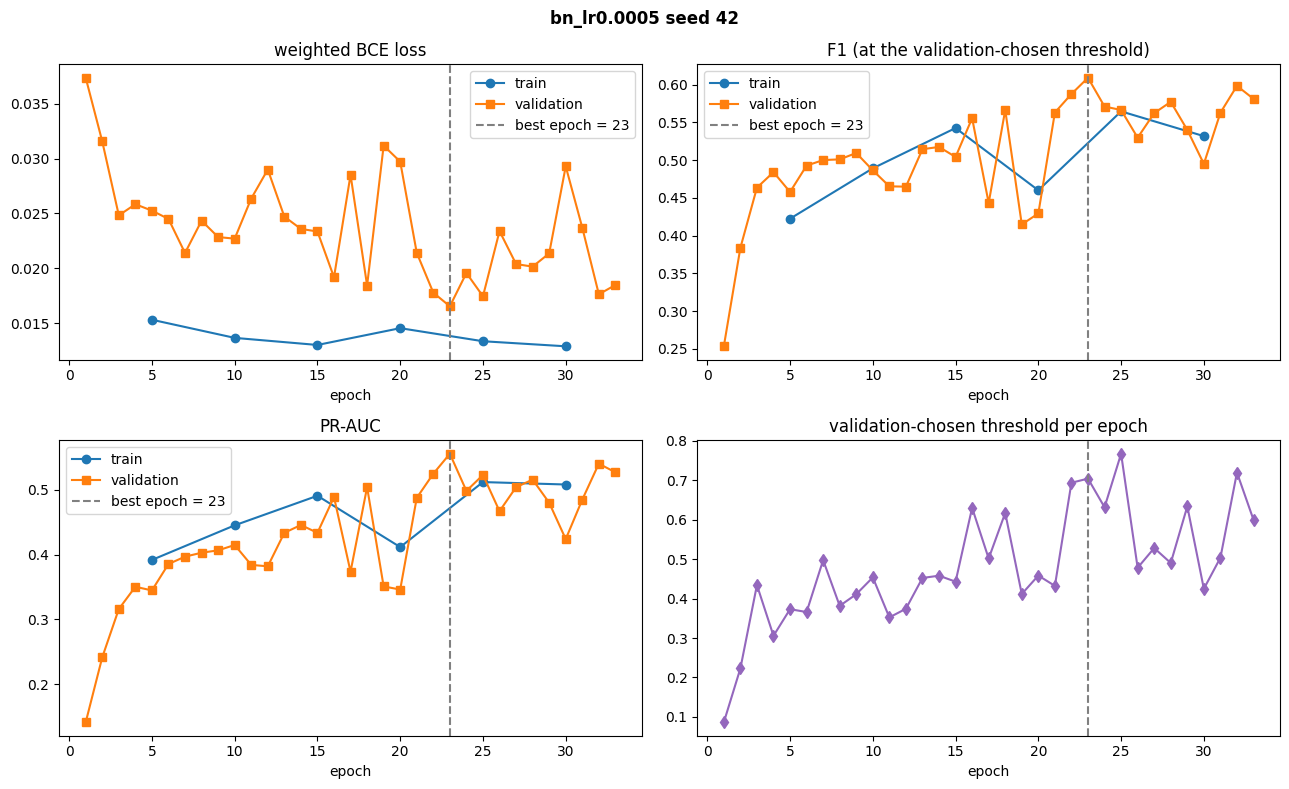

=== bn_lr0.0005 seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0396 | F1   -    / 0.2798 @ 0.079 | PR-AUC   -    / 0.1674 | 51s | RAM 7.0GB   (train / val)   * new best -> best.pt


...

epoch 54 | loss   -    / 0.0238 | F1   -    / 0.5366 @ 0.731 | PR-AUC   -    / 0.4816 | 51s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 55 | loss 0.0095 / 0.0221 | F1 0.6172 / 0.5343 @ 0.853 | PR-AUC 0.6223 / 0.4861 | 83s | RAM 7.1GB   (train / val)
early stop at epoch 55: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6079 at epoch 36 (threshold 0.761) | 55 of 100 epochs run


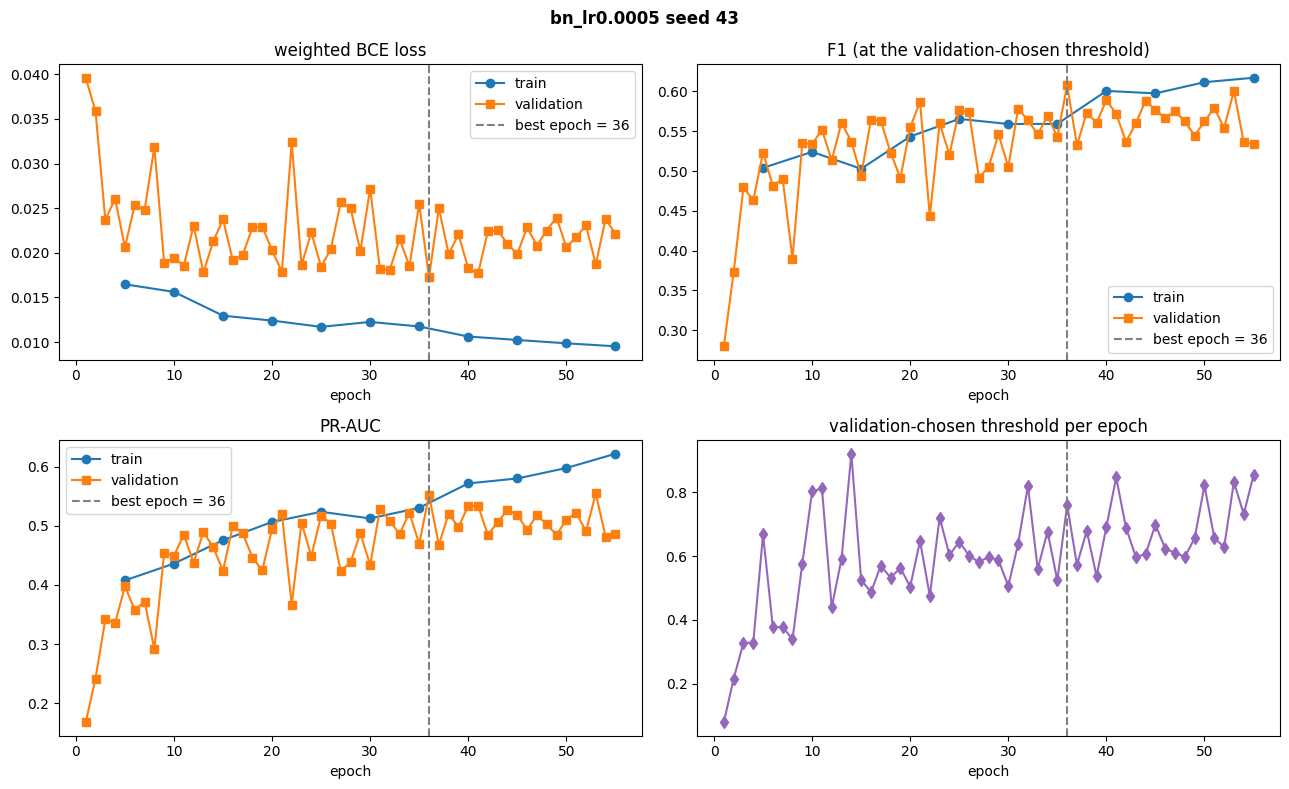

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 33:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 33:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 33:   0%|          | 0/372 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 41 | loss   -    / 0.0199 | F1   -    / 0.5989 @ 0.581 | PR-AUC   -    / 0.5281 | 50s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 42 | loss   -    / 0.0162 | F1   -    / 0.6150 @ 0.809 | PR-AUC   -    / 0.5533 | 50s | RAM 7.5GB   (train / val)
early stop at epoch 42: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6255 at epoch 31 (threshold 0.678) | 42 of 100 epochs run


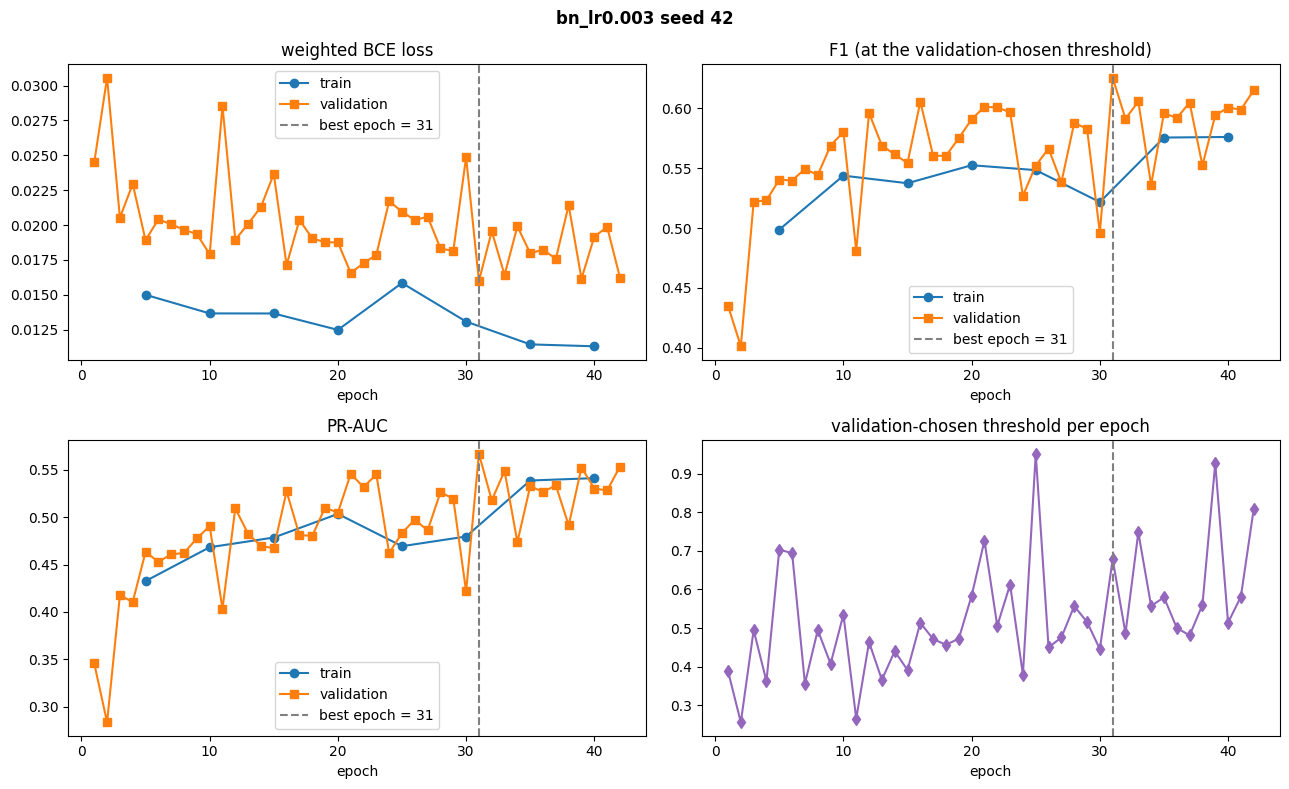

=== bn_lr0.003 seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0277 | F1   -    / 0.4070 @ 0.305 | PR-AUC   -    / 0.3184 | 50s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

epoch 29 | loss   -    / 0.0169 | F1   -    / 0.5690 @ 0.751 | PR-AUC   -    / 0.5098 | 50s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 30 | loss 0.0124 / 0.0215 | F1 0.5560 / 0.5359 @ 0.469 | PR-AUC 0.5093 / 0.4735 | 82s | RAM 7.1GB   (train / val)
early stop at epoch 30: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6058 at epoch 19 (threshold 0.607) | 30 of 100 epochs run


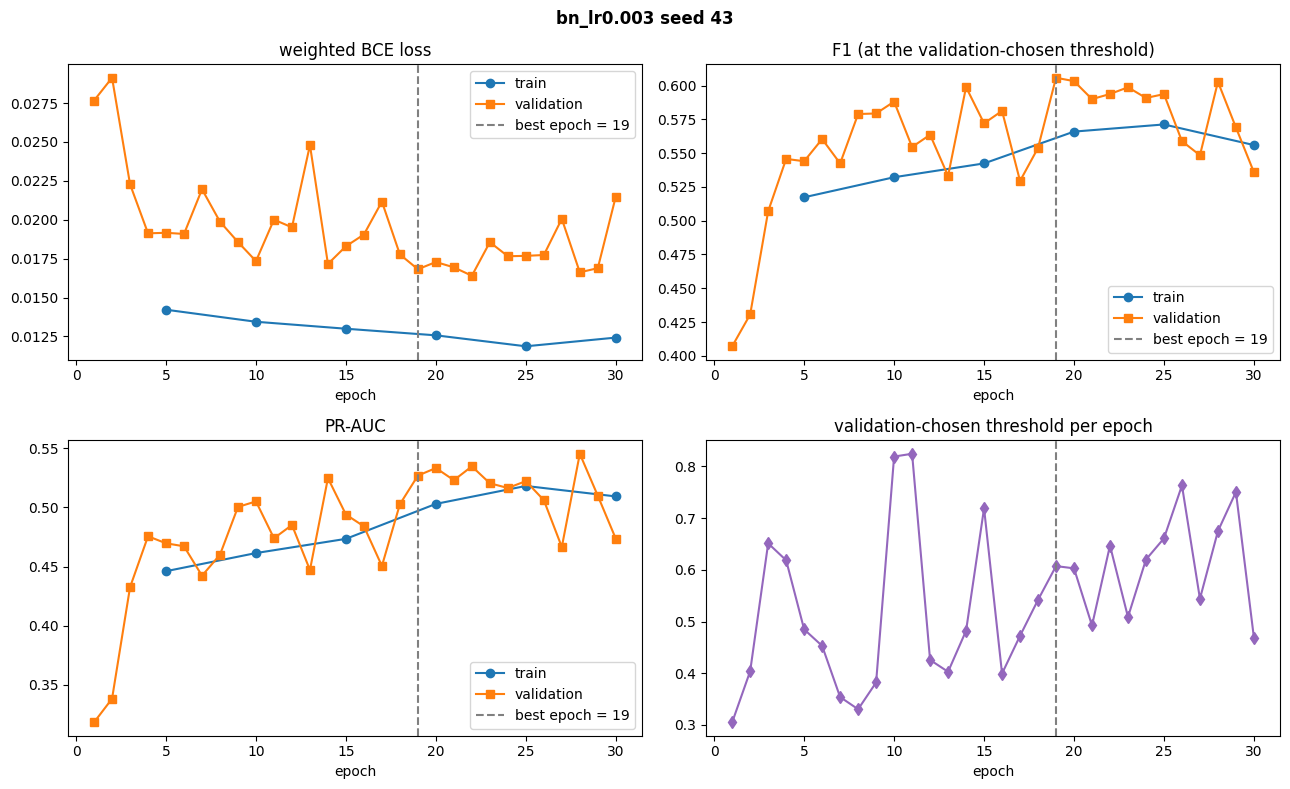

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 22:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 22:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 22:   0%|          | 0/372 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 43 | loss   -    / 0.0342 | F1   -    / 0.4404 @ 0.640 | PR-AUC   -    / 0.3692 | 52s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 44 | loss   -    / 0.0299 | F1   -    / 0.5030 @ 0.642 | PR-AUC   -    / 0.4339 | 51s | RAM 7.5GB   (train / val)
early stop at epoch 44: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6221 at epoch 27 (threshold 0.630) | 44 of 100 epochs run


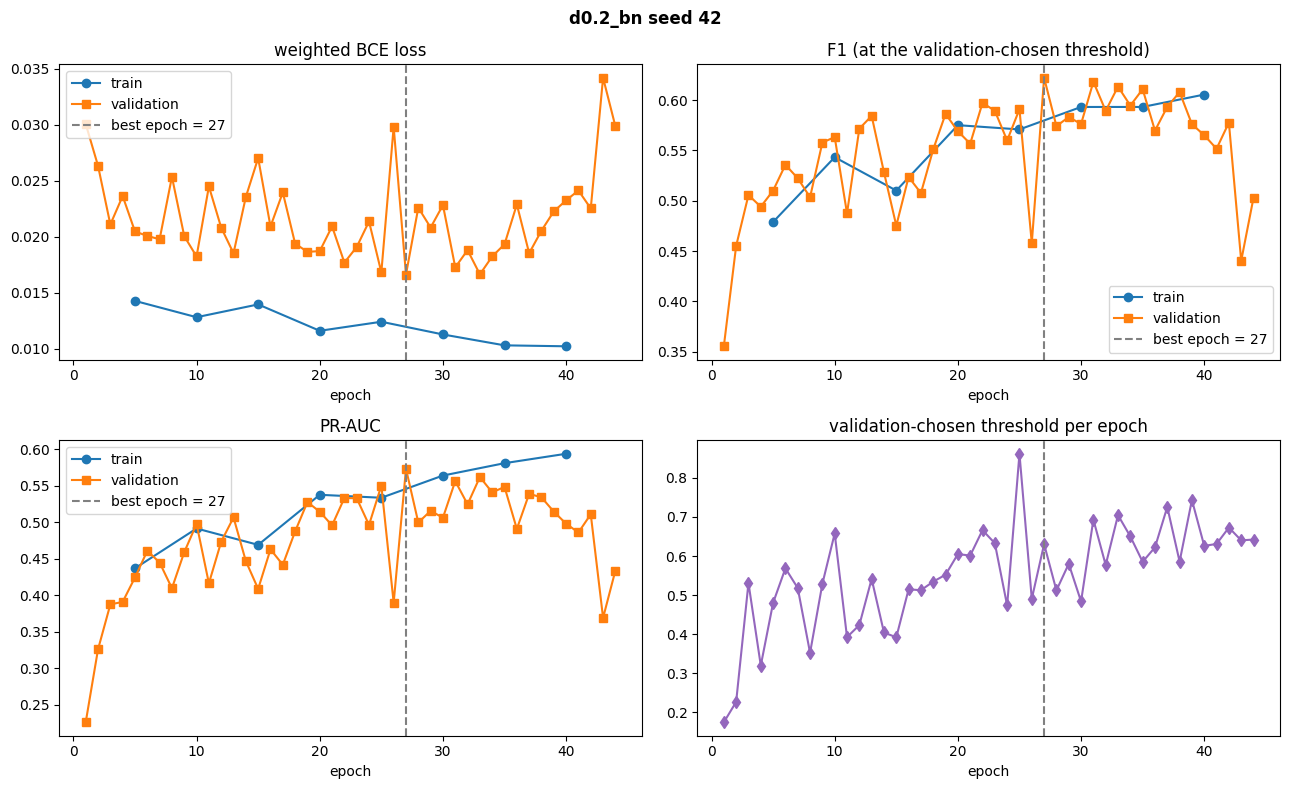

=== d0.2_bn seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0316 | F1   -    / 0.2884 @ 0.426 | PR-AUC   -    / 0.1660 | 51s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 38 | loss   -    / 0.0204 | F1   -    / 0.5653 @ 0.736 | PR-AUC   -    / 0.5212 | 51s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 39 | loss   -    / 0.0220 | F1   -    / 0.5604 @ 0.534 | PR-AUC   -    / 0.5065 | 50s | RAM 7.1GB   (train / val)
early stop at epoch 39: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6002 at epoch 28 (threshold 0.728) | 39 of 100 epochs run


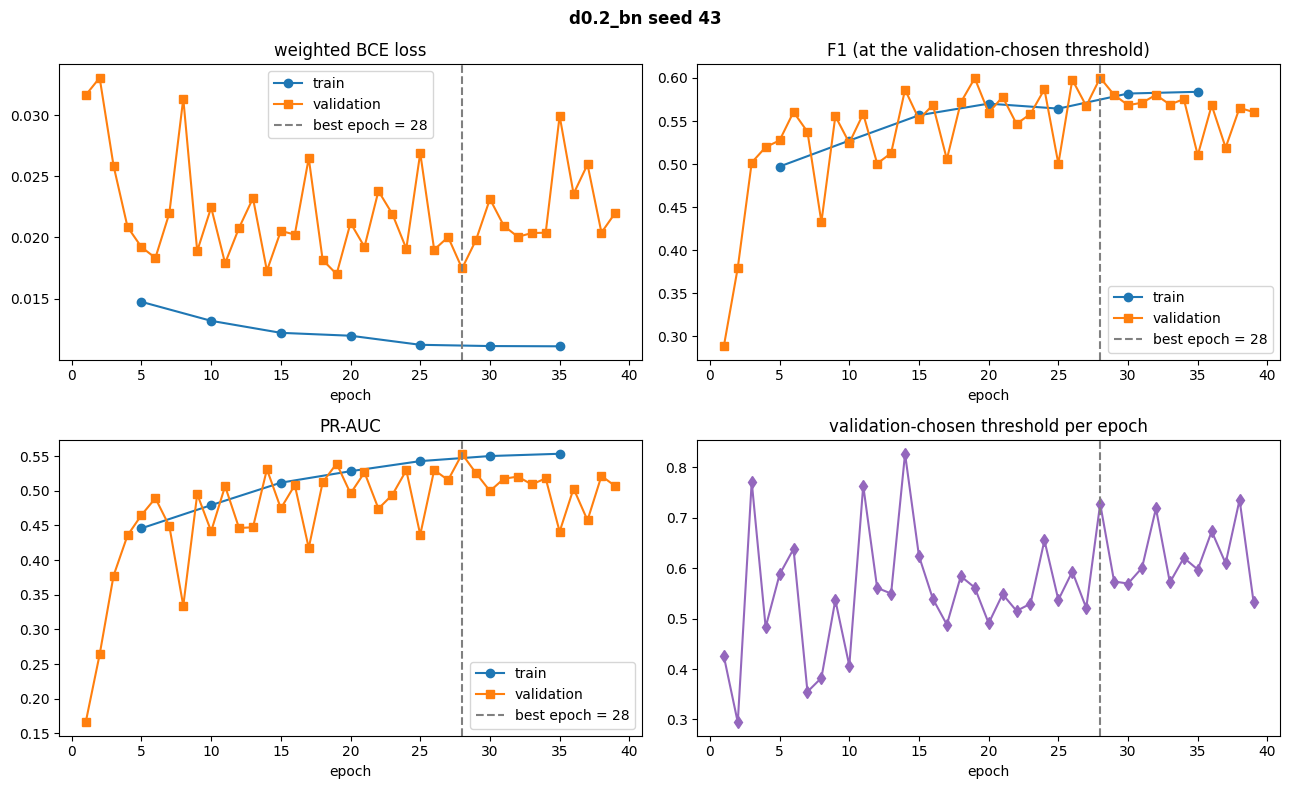

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 32:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 32:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 32:   0%|          | 0/372 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 41 | loss   -    / 0.0241 | F1   -    / 0.5488 @ 0.559 | PR-AUC   -    / 0.4775 | 50s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 42 | loss   -    / 0.0175 | F1   -    / 0.5844 @ 0.756 | PR-AUC   -    / 0.5500 | 50s | RAM 7.5GB   (train / val)
early stop at epoch 42: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6110 at epoch 32 (threshold 0.526) | 42 of 100 epochs run


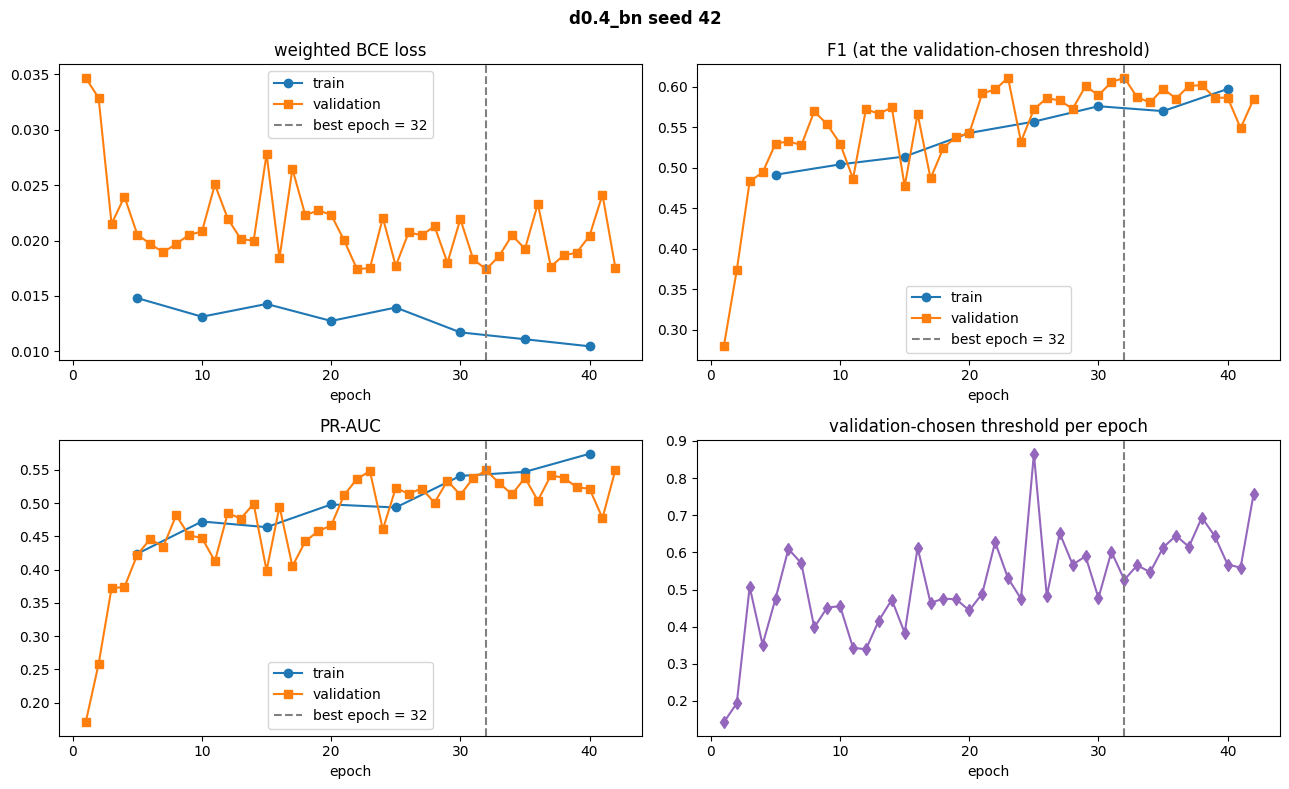

=== d0.4_bn seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0338 | F1   -    / 0.3329 @ 0.145 | PR-AUC   -    / 0.2346 | 50s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

epoch 39 | loss   -    / 0.0208 | F1   -    / 0.5901 @ 0.516 | PR-AUC   -    / 0.5284 | 51s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 40 | loss 0.0108 / 0.0197 | F1 0.5831 / 0.5840 @ 0.691 | PR-AUC 0.5537 / 0.5237 | 84s | RAM 7.1GB   (train / val)
early stop at epoch 40: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6136 at epoch 33 (threshold 0.523) | 40 of 100 epochs run


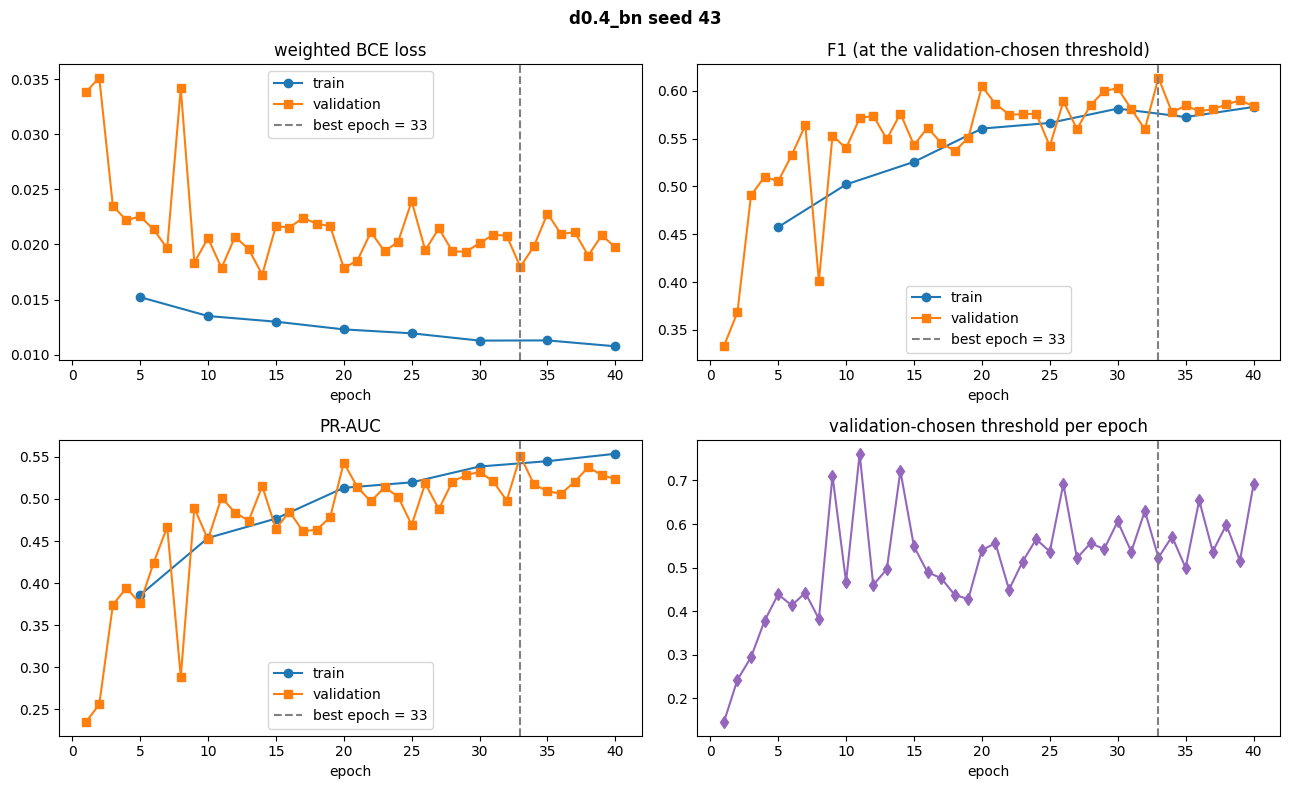

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 30:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 30:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 30:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 43 @ epoch 30:   0%|          | 0/124 [00:00<?, ?it/s]

trial d0.4_bn: best epoch 30 (seed-mean, smoothed) | val F1 0.5957 ± 0.0100 | train F1 0.5786 | gap -0.0171 | epochs run {'42': 42, '43': 40} | checkpoints deleted
winner: bn (val F1 0.6086 ± 0.0190); incumbent bn 0.6086 ± 0.0190
3 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/s6_dropout/stage_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting
>>> after s6_dropout: incumbent = bn | best epoch 34 | {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'batch', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}
all stages complete | incumbent: bn {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'batch', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}


In [6]:
incumbent = core.full_recipe(TUNE)          # the v1 recipe + T_max 100; each stage may replace one knob
incumbent_trial, winners = None, {}
for stage, knob, grid in STAGES:
    stage_dir = f'{OUT_ROOT}/{stage}'
    os.makedirs(stage_dir, exist_ok=True)
    trials, recipes = [], {}
    for value in grid:
        recipe = core.with_knob(incumbent, knob, value, NEIGHBOURS_USED)
        if recipe is None:
            print(f'{stage}: {knob} = {value} skipped (depth dropped by the probe)')
            continue
        trial = core.run_tuning_trial(OPERATOR, CFG, graphs, col_sets, node_dim, stage_dir, recipe, SEEDS, TUNE,
                                      MP_DIRECTION, TEMPORAL_SAMPLING, EVAL_TRAIN_EVERY, PATIENCE, MIN_EPOCHS,
                                      reuse=incumbent_trial)
        trials.append(trial)
        recipes[trial['trial']] = recipe
    winner = core.choose_winner(trials, core.recipe_tag(incumbent, TUNE))

    # edge rule: a numeric winner at the edge of its grid gets one trial one step beyond
    beyond = core.edge_value(knob, winner['recipe'][knob], grid)
    if beyond is not None:
        if knob == 'num_layers' and beyond not in NEIGHBOURS_USED:
            extra_probe = core.probe_depths(OPERATOR, CFG, graphs, col_sets, node_dim, HEAVIEST, (beyond,),
                                            f'{OUT_ROOT}/probe_{beyond}L.json', mp_direction=MP_DIRECTION,
                                            temporal=TEMPORAL_SAMPLING, reference_seconds=probe['reference_seconds'])
            NEIGHBOURS_USED = core.neighbours_from_probe(extra_probe, NEIGHBOURS_USED)
        recipe = core.with_knob(winner['recipe'], knob, beyond, NEIGHBOURS_USED)
        if recipe is None:
            print(f'{stage}: edge trial {knob} = {beyond} skipped (depth failed the probe)')
        else:
            extra = core.run_tuning_trial(OPERATOR, CFG, graphs, col_sets, node_dim, stage_dir, recipe, SEEDS, TUNE,
                                          MP_DIRECTION, TEMPORAL_SAMPLING, EVAL_TRAIN_EVERY, PATIENCE, MIN_EPOCHS)
            trials.append(extra)
            recipes[extra['trial']] = recipe
            winner = core.choose_winner(trials, winner['trial'])

    incumbent, incumbent_trial, winners[stage] = recipes[winner['trial']], winner, winner['trial']
    core.summarize_stage(stage_dir, winner['trial'])
    print(f">>> after {stage}: incumbent = {winner['trial']} | best epoch {winner['best_epoch']} | {incumbent}")
print('=' * 90)
print('all stages complete | incumbent:', incumbent_trial['trial'], incumbent)

## 5. Summary across the stages

- `trials_summary.csv`: one row per trial with every knob, best / stopped epochs, train and validation F1 / PR-AUC (mean ± std), the train − val gap and the winner flag.
- Gap caveat: validation has 0.107 % laundering vs 0.075 % on train, so part of any gap is prevalence, not underfitting.
- `tuning_curves.png`: seed-mean validation F1 per epoch, one line per trial, winners bold.

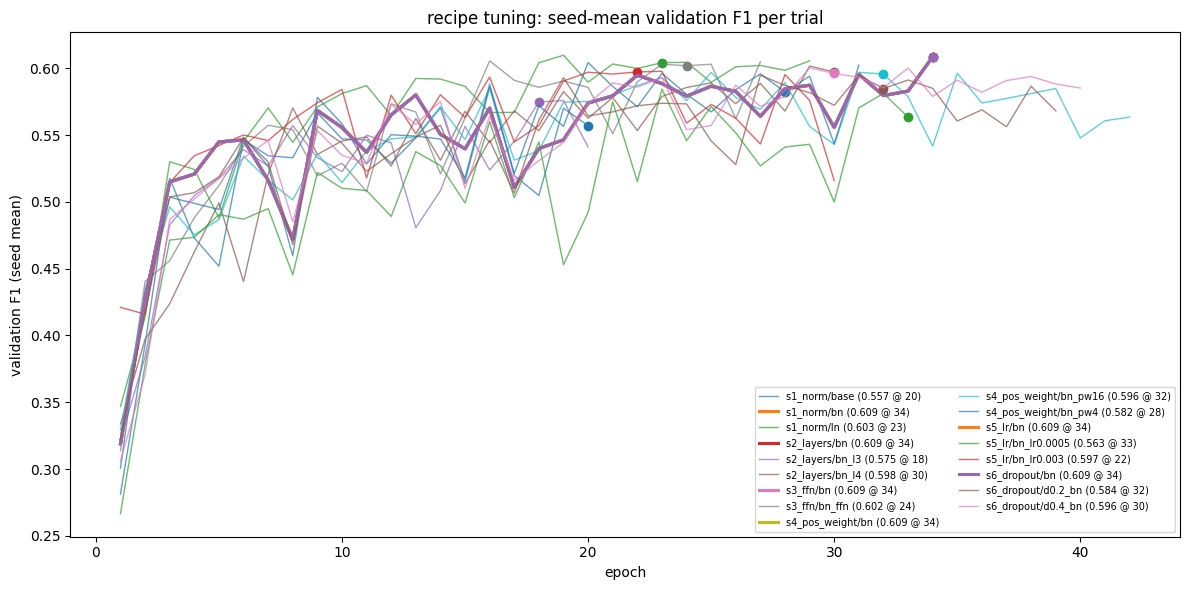

17 trials -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/trials_summary.csv | train - val gap: validation has 0.107 % laundering vs 0.075 % on train, so part of the gap is prevalence, not underfitting


,stage,trial,winner,dropout,norm,num_layers,num_neighbors,pos_weight,lr,ffn,...,epochs_run,reached_max,val_f1_mean,val_f1_std,train_f1_mean,gap_f1,val_pr_auc_mean,thresholds,params,invariant_params
0,s1_norm,base,False,0.3,none,2,100-100,8.0,0.0010,False,...,20/33,False,0.5566,0.0367,0.5389,-0.0177,0.4989,0.460/0.521,108419,67587
1,s1_norm,bn,True,0.3,batch,2,100-100,8.0,0.0010,False,...,34/44,False,0.6086,0.0190,0.5896,-0.0190,0.5400,0.653/0.656,108931,68099
2,s1_norm,ln,False,0.3,layer,2,100-100,8.0,0.0010,False,...,34/29,False,0.6033,0.0354,0.6002,-0.0031,0.5427,0.735/0.574,108931,68099
3,s2_layers,bn,True,0.3,batch,2,100-100,8.0,0.0010,False,...,34/44,False,0.6086,0.0190,0.5896,-0.0190,0.5400,0.653/0.656,108931,68099
4,s2_layers,bn_l3,False,0.3,batch,3,100-100-50,8.0,0.0010,False,...,20/39,False,0.5746,0.0019,0.5460,-0.0286,0.5099,0.500/0.495,145156,101636
5,s2_layers,bn_l4,False,0.3,batch,4,100-100-50-50,8.0,0.0010,False,...,30/51,False,0.5976,0.0082,0.5810,-0.0166,0.5263,0.517/0.642,181381,135173
6,s3_ffn,bn,True,0.3,batch,2,100-100,8.0,0.0010,False,...,34/44,False,0.6086,0.0190,0.5896,-0.0190,0.5400,0.653/0.656,108931,68099
7,s3_ffn,bn_ffn,False,0.3,batch,2,100-100,8.0,0.0010,True,...,35/27,False,0.6015,0.0114,0.5630,-0.0385,0.5330,0.633/0.481,241283,200451
8,s4_pos_weight,bn,True,0.3,batch,2,100-100,8.0,0.0010,False,...,34/44,False,0.6086,0.0190,0.5896,-0.0190,0.5400,0.653/0.656,108931,68099
9,s4_pos_weight,bn_pw16,False,0.3,batch,2,100-100,16.0,0.0010,False,...,42/43,False,0.5957,0.0051,0.5776,-0.0181,0.5384,0.784/0.798,108931,68099


In [7]:
summary = core.summarize_tuning(OUT_ROOT, winners)
summary[['stage', 'trial', 'winner', 'dropout', 'norm', 'num_layers', 'num_neighbors', 'pos_weight', 'lr', 'ffn',
         'best_epoch', 'epochs_run', 'reached_max', 'val_f1_mean', 'val_f1_std', 'train_f1_mean', 'gap_f1',
         'val_pr_auc_mean', 'thresholds', 'params', 'invariant_params']].round(4)

## 6. Freeze the recipe

- Only after every stage has run: `recipe.json` = knobs, neighbour lists, T_max, best epoch, per-seed thresholds for the four retrain seeds (42 and 43 their own; 44 and 45 the mean of those two), the validation F1 that chose them.
- This file is the single source of the frozen GIN recipe; `GIN_tuning_final.ipynb` loads it.

In [8]:
assert set(winners) == {stage for stage, _, _ in STAGES}, 'run every stage before freezing the recipe'
frozen = core.save_recipe(f'{OUT_ROOT}/recipe.json', OPERATOR, CFG, incumbent_trial)

frozen recipe -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/recipe.json
{
 "operator": "gin",
 "cfg": {
  "mp": "base",
  "readout": "base"
 },
 "recipe": {
  "hidden": 128,
  "num_layers": 2,
  "dropout": 0.3,
  "norm": "batch",
  "ffn": false,
  "num_neighbors": [
   100,
   100
  ],
  "batch_size": 8192,
  "epochs": 100,
  "lr": 0.001,
  "weight_decay": 1e-05,
  "pos_weight": 8.0
 },
 "best_epoch": 34,
 "tuning_seeds": [
  42,
  43
 ],
 "retrain_seeds": [
  42,
  43,
  44,
  45
 ],
 "thresholds": {
  "42": 0.6528624892234802,
  "43": 0.6556033492088318,
  "44": 0.654232919216156,
  "45": 0.654232919216156
 },
 "threshold_source": "tuning seeds: own validation threshold at best_epoch; other seeds: mean of the tuning seeds",
 "val_f1_mean": 0.6085806996100344,
 "val_f1_std": 0.018950428810741226,
 "train_f1_mean": 0.5896203383724182,
 "epochs_run": {
  "42": 34,
  "43": 44
 },
 "source_stage": "s6_dropout",
 "source_trial": "bn"
}


## 7. Download

- Zip `OUT_ROOT`; extract into `Outputs/TUNING/GIN/` in the repo and commit the small files (`trial.json`, `history.csv`, `curves.png`, summaries, `probe.json`, `recipe.json`; `best.pt` stays out of git).

In [9]:
import shutil
shutil.make_archive('/kaggle/working/Outputs_TUNING_GIN', 'zip', OUT_ROOT)

'/kaggle/working/Outputs_TUNING_GIN.zip'